Import libraries and load dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [10]:
df = pd.read_csv("Ecommerce Customers.csv")

print("Dataset Shape:", df.shape)
print("\nColumns:\n", df.columns.tolist())
print("\nMissing Values:\n", df.isnull().sum())
df.head()

Dataset Shape: (500, 8)

Columns:
 ['Email', 'Address', 'Avatar', 'Avg. Session Length', 'Time on App', 'Time on Website', 'Length of Membership', 'Yearly Amount Spent']

Missing Values:
 Email                   0
Address                 0
Avatar                  0
Avg. Session Length     0
Time on App             0
Time on Website         0
Length of Membership    0
Yearly Amount Spent     0
dtype: int64


,Email,Address,Avatar,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,mstephenson@fernandez.com,"835 Frank Tunnel\nWrightmouth, MI 82180-9605",Violet,34.497268,12.655651,39.577668,4.082621,587.951054
1,hduke@hotmail.com,"4547 Archer Common\nDiazchester, CA 06566-8576",DarkGreen,31.926272,11.109461,37.268959,2.664034,392.204933
2,pallen@yahoo.com,"24645 Valerie Unions Suite 582\nCobbborough, DC 99414-7564",Bisque,33.000915,11.330278,37.110597,4.104543,487.547505
3,riverarebecca@gmail.com,"1414 David Throughway\nPort Jason, OH 22070-1220",SaddleBrown,34.305557,13.717514,36.721283,3.120179,581.852344
4,mstephens@davidson-herman.com,"14023 Rodriguez Passage\nPort Jacobville, PR 37242-1057",MediumAquaMarine,33.330673,12.795189,37.536653,4.446308,599.406092


Feature engineering

In [11]:
# Create interaction-based features
# Create interaction-based features
df["App_Website_Ratio"] = (df["Time on App"] / (df["Time on Website"] + 1e-8))

df["Engagement_Index"] = (df["Time on App"] + df["Time on Website"])

print(df[[
    "Time on App",
    "Time on Website",
    "App_Website_Ratio",
    "Engagement_Index"
]].head())

   Time on App  Time on Website  App_Website_Ratio  Engagement_Index
0    12.655651        39.577668           0.319767         52.233319
1    11.109461        37.268959           0.298089         48.378420
2    11.330278        37.110597           0.305311         48.440875
3    13.717514        36.721283           0.373558         50.438796
4    12.795189        37.536653           0.340872         50.331842


Check relationships visually

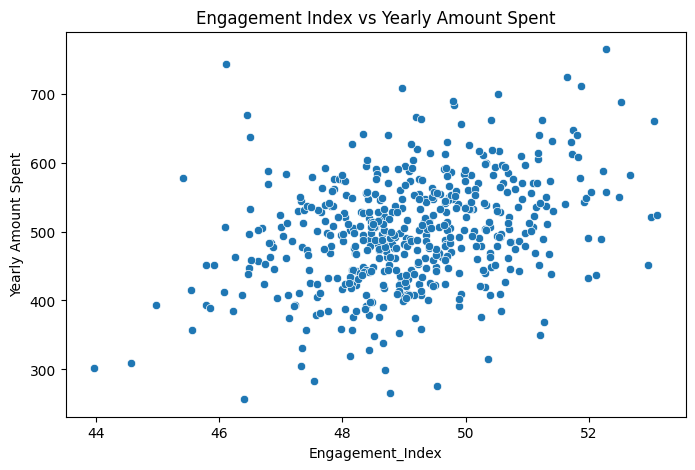

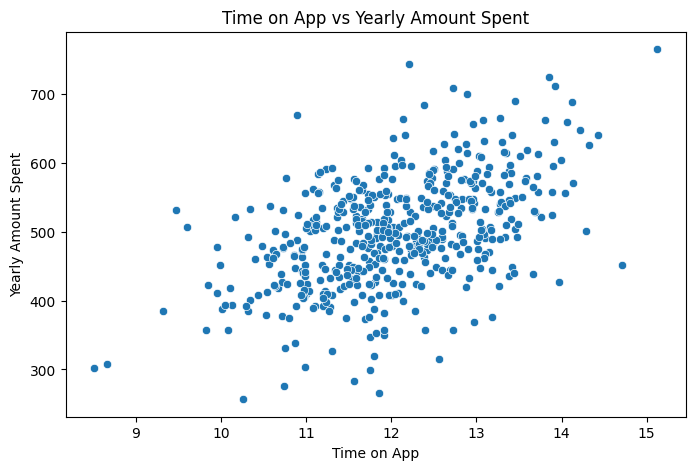

In [4]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Engagement_Index", y="Yearly Amount Spent")
plt.title("Engagement Index vs Yearly Amount Spent")
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Time on App", y="Yearly Amount Spent")
plt.title("Time on App vs Yearly Amount Spent")
plt.show()

Generate polynomial features and compare models

In [6]:
# Select numerical input features
base_features = ["Avg. Session Length", "Time on App", "Time on Website", "Length of Membership"]

engineered_features = base_features + ["App_Website_Ratio", "Engagement_Index"]

target = "Yearly Amount Spent"

# Handle missing values for this analysis
model_df = df[engineered_features + [target]].copy()
model_df = model_df.replace([np.inf, -np.inf], np.nan).dropna()


X_base = model_df[base_features]
X_engineered = model_df[engineered_features]
y = model_df[target]


Xb_train, Xb_test, y_train, y_test = train_test_split(X_base, y, test_size=0.2, random_state=42)

Xe_train, Xe_test, _, _ = train_test_split(X_engineered, y, test_size=0.2, random_state=42)

baseline_model = make_pipeline(StandardScaler(), LinearRegression())

baseline_model.fit(Xb_train, y_train)
baseline_pred = baseline_model.predict(Xb_test)

# Polynomial model
polynomial_model = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)
polynomial_model.fit(Xe_train, y_train)
polynomial_pred = polynomial_model.predict(Xe_test)

# Evaluation
results = pd.DataFrame({
    "Model": ["Baseline Linear Regression", "Engineered + Polynomial"],
    "R2 Score": [
        r2_score(y_test, baseline_pred),
        r2_score(y_test, polynomial_pred)
    ],
    "MAE": [
        mean_absolute_error(y_test, baseline_pred),
        mean_absolute_error(y_test, polynomial_pred)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, baseline_pred)),
        np.sqrt(mean_squared_error(y_test, polynomial_pred))
    ]
})

results.round(4)

,Model,R2 Score,MAE,RMSE
0,Baseline Linear Regression,0.9778,8.5584,10.4816
1,Engineered + Polynomial,0.9766,8.8044,10.7644


Visualize model performance

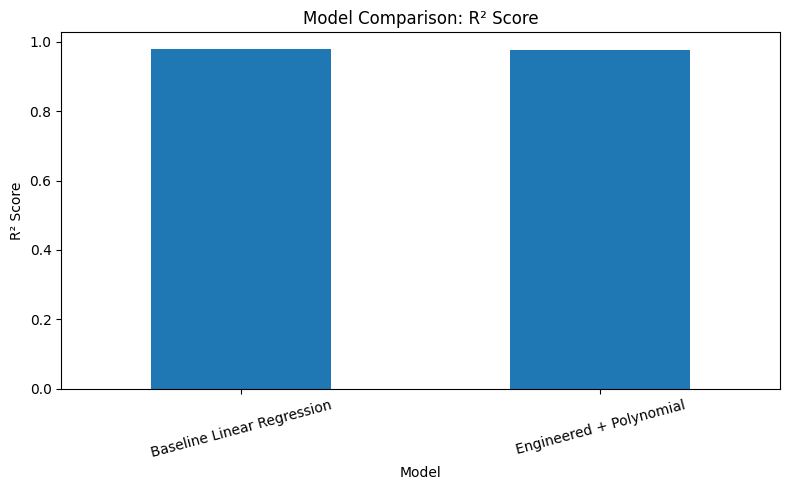

In [8]:
results.set_index("Model")["R2 Score"].plot(kind='bar', figsize=(8,5))

plt.title("Model Comparison: R² Score")
plt.ylabel("R² Score")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

Save your results

In [9]:
df.to_csv("task20_engineered_dataset.csv", index=False)
results.to_csv("task20_model_comparison.csv", index=False)

print("Task 20 output files saved successfully.")

Task 20 output files saved successfully.


Conclusion – Task 20


In this task, the Ecommerce Customers dataset containing 500 records and 8 columns was analyzed. No missing values were found. Two interaction-based features, App-to-Website Ratio and Engagement Index, were created to represent customer usage behavior. Polynomial features of degree 2 were then generated to capture potential nonlinear relationships. The Baseline Linear Regression model achieved an R² score of 0.9778, MAE of 8.5584, and RMSE of 10.4816. The Engineered + Polynomial model achieved an R² score of 0.9766, MAE of 8.8044, and RMSE of 10.7644. Therefore, the baseline model performed slightly better on the test data. This shows that adding interaction-based and polynomial features did not improve predictive performance in this experiment, although the engineered features provide additional ways to analyze customer engagement and spending behavior.